# Building Backtesting Framework and Performance Measurements

The goal of this notebook is to understand how a backtest and PnL curve is generated

In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Paths and Global Variables

In [2]:
note_path = os.getcwd()
repo_path = os.path.abspath(os.path.join(note_path, ".."))
data_path = os.path.join(repo_path, "data")
zone_path = os.path.join(data_path, "ZoneImputedFirstRateData")

In [3]:
import sys; sys.path.append(os.path.join(repo_path, "src"))
from SignalGenerator import SignalGenerator

In [55]:
day_renamer = {
    "day_after"   : "Day After",
    "day_before"  : "Day Before",
    "post_meeting": "Post Meeting",
    "pre_meeting" : "Pre Meeting"}

zone_renamer = {
    "zone1": "Day Before",
    "zone2": "Before Meeting",
    "zone3": "After Meeting",
    "zone4": "Day After"}

sample_renamer = {
    "lday_vol" : "Prior Day",
    "lzone_vol": "Prior Event"}

vol_renamer = {
    "lday"       : "Prior Day",
    "lzone"      : "Prior Event",
    "combined"   : "Prior Day and Event",
    "raw_rtn"    : "Raw Return",
    "impute_open": "Raw Return"}

param_renamer = {
    "const"    : "Const",
    "lday_vol" : "Prior Day Vol",
    "lzone_vol": "Prio Event Vol"}

tmp_renamer = {
    "name"    : "Trading Zone",
    "vol_type": "Vol Estimator",
    "ticker"  : "Contract"}

sample_renamer_ = {
    "in_sample" : "In-Sample",
    "out_sample": "Out-Sample",
    "train_test": "Train-Test"}

replacer = {**day_renamer, **zone_renamer, **sample_renamer, **param_renamer, **vol_renamer, **tmp_renamer, **sample_renamer_}

# Calculating the backtest

One of the problems of generating PnL curves is the following
1. non-continuous times
2. each contract trading at different durations / vols and thus not normalized

In [5]:
path    = os.path.join(data_path, r"ZoneImputedFirstRateData")
df_zone = (pd
    .read_parquet(path = path)
    .loc[lambda x: x.ticker != "ZQ"]
    .set_index("date")
    [["meeting_id", "ticker", "contract", "impute_open", "zone", "name"]])

In [6]:
df_pnl = (df_zone
    .groupby(["meeting_id", "ticker", "contract", "zone", "name"])
    .apply(lambda x: x.sort_index().impute_open.diff())
    .reset_index())

Text(0.5, 1.0, 'Cumulative PnL of Volatility Targeted PnLs Hedged Perfectly and Minutely\nUsing 10d EWMA')

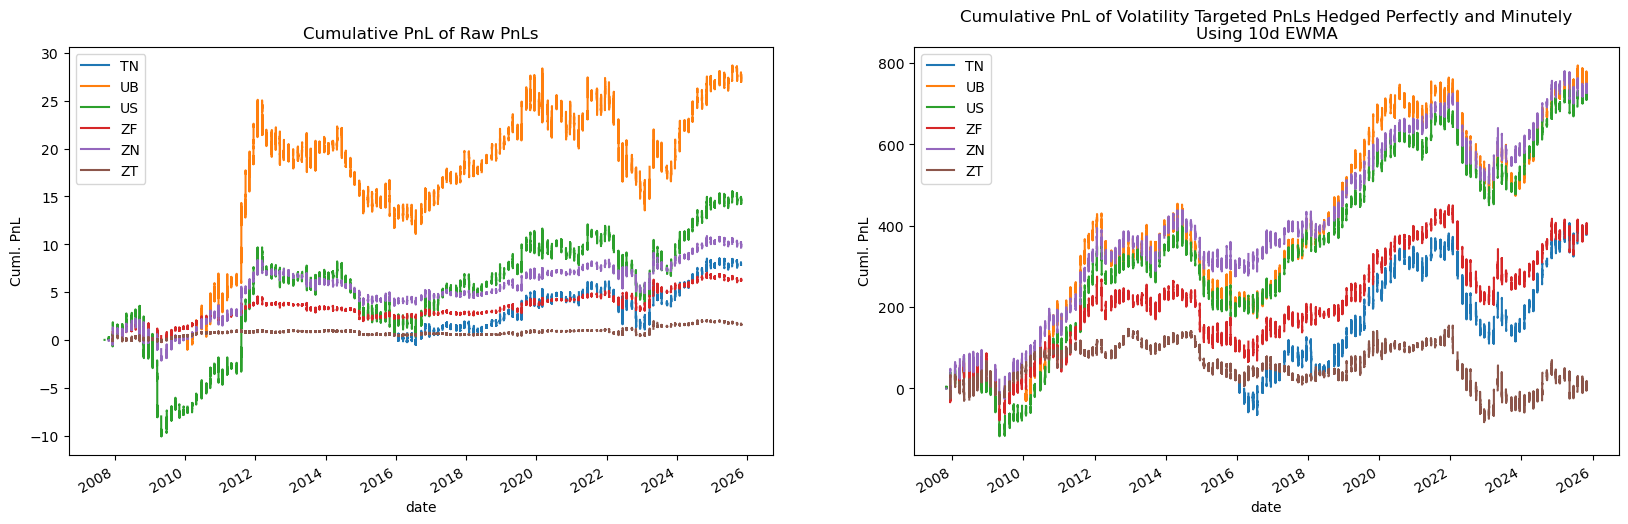

In [7]:
fig, axes = plt.subplots(ncols = 2, figsize = (20,6))

(df_pnl
    .rename(columns = {"ticker": ""})
    .pivot(index = "date", columns = "", values = "impute_open")
    .cumsum()
    .plot(
        ax = axes[0]))

(df_pnl
    .rename(columns = {"ticker": ""})
    .pivot(index = "date", columns = "", values = "impute_open")
    .apply(lambda x: x / x.ewm(span = 10, adjust = False).std())
    .apply(lambda x: np.where(np.abs(x) > 50, np.nan, x))
    .cumsum()
    .plot(
        ax = axes[1]))

for ax in axes.flatten(): 
    ax.set_ylabel("Cuml. PnL")

axes[0].set_title("Cumulative PnL of Raw PnLs")
axes[1].set_title("Cumulative PnL of Volatility Targeted PnLs Hedged Perfectly and Minutely\nUsing 10d EWMA")

The PnLs need some sort of volatility targeting to noramlize the returns when we make the portfolio. On the other hand its not possible to hedge, and perfectly as well, at the minutely level. Therefore we need a volatility targeting tool that does the following
1. Calcluates a hedge value per every trade
2. Keeps the PnL in line with the initial hedge values
3. Also use the prior price action data (which isn't present in the trading zones) data, and thus properly hedge. 

# Finding the optimal volatility calculation

Ideally we want to find a volatility measurement that accurately sets a volatility target. Using the historical data, there are two options 
1. We can use the prior day's volatility calculation which comes from the data
2. We can use the prior event's volatility calculation

At this moment there are arguments for either since the prior day's volatility may capture the macro economic backdrop greater than the prior event, yet the whole point of this repo is to trade a repeatable pattern around FOMC announcements. Therefore we'll test both and see which is better. 

In [8]:
path         = os.path.join(data_path, "Volatilities", "CombinedVolEstimators.parquet")
df_vol_panel = (pd.read_parquet(path = path))

In [9]:
df_day_before = (df_vol_panel
    .loc[lambda x: x.name == "day_before"]
    .assign(
        lzone_vol = lambda x: np.log(x.lzone_vol),
        cur_vol   = lambda x: np.log(x.cur_vol),
        lday_vol  = lambda x: np.log(x.lday_vol)))

C:\Users\Diego\anaconda3\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


When comparing the log volatilities estimators there is a strong linear relationship. Below is a plot showing the relationship between the prior day's volatility (for the corresopnding zone) and the prior event's volatility (prior meeting) volatility. 

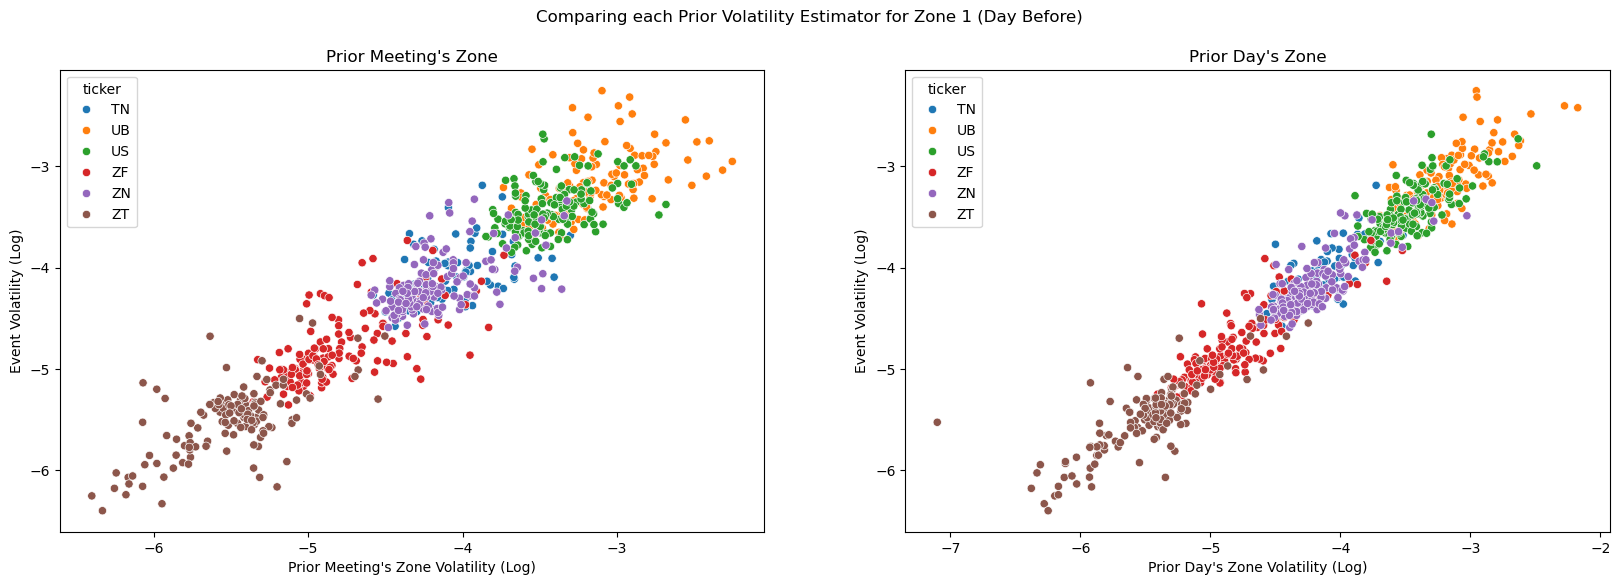

In [10]:
fig, axes   = plt.subplots(ncols = 2, figsize = (20,6))
vol_renamer = {
    "lzone_vol": "Prior Meeting's Zone", 
    "lday_vol" : "Prior Day's Zone"}

for i, vol in enumerate(vol_renamer.keys()):

    sns.scatterplot(
        ax   = axes[i],
        data = df_day_before,
        x    = vol,
        y    = "cur_vol",
        hue  = "ticker")

    axes[i].set_ylabel("Event Volatility (Log)")
    axes[i].set_xlabel(vol_renamer[vol] + " Volatility (Log)")
    axes[i].set_title(vol_renamer[vol])

fig.suptitle("Comparing each Prior Volatility Estimator for Zone 1 (Day Before)")
plt.show()

In [11]:
df_tn_vol = (df_vol_panel
    .loc[lambda x: x.ticker == x.ticker.min()]
    [["name", "lzone_vol", "cur_vol", "lday_vol"]]
    .set_index("name")
    .reset_index()
    .replace(replacer))

It appears that the relationship is not strong when comparing them across different zones. This implies that different periods around FOMC announcements have non uniform volatility structures. Notice on the left hand of the plot the prior meeting times appears to have a more linear relationship than the prior day's. This shows that it was right to be cautious about using the prior day's volatility. 

Text(0.5, 0.98, 'Comparing each Prior Volatility Estimator for TN Futures')

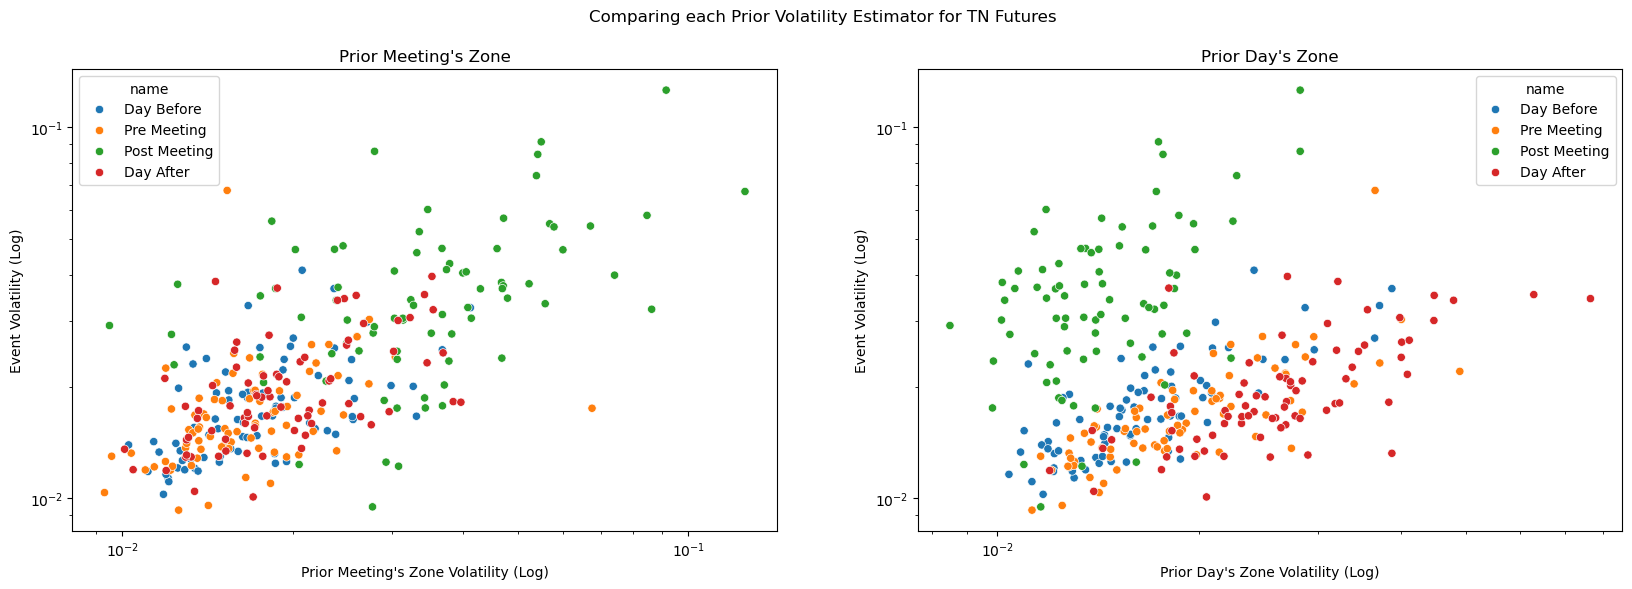

In [12]:
fig, axes   = plt.subplots(ncols = 2, figsize = (20,6))
vol_renamer = {
    "lzone_vol": "Prior Meeting's Zone", 
    "lday_vol" : "Prior Day's Zone"}

for i, vol in enumerate(vol_renamer.keys()):

    sns.scatterplot(
        ax   = axes[i],
        data = df_tn_vol,
        x    = vol,
        y    = "cur_vol",
        hue  = "name")

    axes[i].set_xscale("log")
    axes[i].set_yscale("log")
    
    axes[i].set_ylabel("Event Volatility (Log)")
    axes[i].set_xlabel(vol_renamer[vol] + " Volatility (Log)")
    axes[i].set_title(vol_renamer[vol])

fig.suptitle("Comparing each Prior Volatility Estimator for TN Futures")

Before setting up the first model for testing start by deciding if we have enough data to begin. Below is a table its reasonable but we have to consider that a full out-of-sample model diminishes the data size. 

In [13]:
(df_vol_panel
    [["ticker", "name", "lag_contract"]]
    .groupby(["ticker", "name"])
    .agg("count")
    .reset_index()
    .rename(columns = {"name": ""})
    .pivot(index = "ticker", columns = "", values = "lag_contract")
    .rename(columns = replacer))

,Day After,Day Before,Post Meeting,Pre Meeting
ticker,,,,
TN,77,78,77,78
UB,126,126,126,126
US,145,145,144,144
ZF,142,141,140,142
ZN,143,143,142,142
ZT,143,143,143,142


When comparing raw correlations it appears that the the prior day volatility is a better estimator

In [14]:
df_vol_corr = (df_vol_panel
    [["ticker", "name", "cur_vol", "lzone_vol", "lday_vol"]]
    .melt(id_vars = ["ticker", "name", "cur_vol"])
    .groupby(["ticker", "name", "variable"])
    .agg("corr")
    .reset_index()
    .drop(columns = ["level_3", "cur_vol"])
    .loc[lambda x: x.value != 1])

display(df_vol_corr
    .rename(columns = {"name": ""})
    .replace(replacer)
    .pivot(index = ["ticker", "variable"], columns = "", values = "value"))

Day After  Day Before  Post Meeting  Pre Meeting
ticker variable                                                        
TN     Prio Event Vol   0.502237    0.481407      0.518249     0.212476
       Prior Day Vol    0.633238    0.768213      0.592879     0.643383
UB     Prio Event Vol   0.475043    0.418571      0.407737     0.250602
       Prior Day Vol    0.627908    0.752141      0.511992     0.560531
US     Prio Event Vol   0.331088    0.413897      0.256174     0.198990
       Prior Day Vol    0.377306    0.419062      0.426415     0.522958
ZF     Prio Event Vol   0.386387    0.619376      0.475947     0.304388
       Prior Day Vol    0.463760    0.829419      0.591029     0.684044
ZN     Prio Event Vol   0.366195    0.534727      0.436068     0.298285
       Prior Day Vol    0.378734    0.808704      0.533474     0.626716
ZT     Prio Event Vol   0.588373    0.614421      0.574599     0.396211
       Prior Day Vol    0.670684    0.816100      0.305442     0.748744

The Prior Day volatility estimate adds a reasonable amount of extra correlation for almost all scenarios

In [15]:
(df_vol_corr
    .pivot(index = ["ticker", "name"], columns = "variable", values = "value")
    .assign(extra_corr = lambda x: x.lday_vol - x.lzone_vol)
    .reset_index()
    .rename(columns = {"name": ""})
    .replace(replacer)
    .pivot(index = "ticker", columns = "", values = "extra_corr"))

,Day After,Day Before,Post Meeting,Pre Meeting
ticker,,,,
TN,0.131001,0.286806,0.074630,0.430907
UB,0.152865,0.333570,0.104255,0.309930
US,0.046218,0.005165,0.170241,0.323968
ZF,0.077373,0.210043,0.115082,0.379656
ZN,0.012538,0.273977,0.097406,0.328431
ZT,0.082310,0.201679,-0.269157,0.352533


There is reason to believe that adding the Lagged Perior Volatility since the correlation between the two exoegenous factors is quite low. 

In [16]:
(df_vol_panel
    [["ticker", "name", "lzone_vol", "lday_vol"]]
    .groupby(["ticker", "name"])
    .agg("corr")
    .loc[lambda x: x.lday_vol != 1]
    .reset_index()
    .rename(columns = {"name": ""})
    .replace(replacer)
    .pivot(index = "ticker", columns = "", values = "lday_vol"))

,Day After,Day Before,Post Meeting,Pre Meeting
ticker,,,,
TN,0.429402,0.482172,0.441947,0.311838
UB,0.383314,0.473031,0.335469,0.268674
US,0.220396,0.195895,0.250763,0.250457
ZF,0.390400,0.570838,0.374510,0.380270
ZN,0.367540,0.542325,0.361849,0.362061
ZT,0.464224,0.581968,0.148377,0.517937


Now start by analyzing the full sample OLS parameters. 3 regressions are run per group per ticker
1. Using prior day volatility
2. Using prior event volatility
3. Using Both

In [17]:
path      =  os.path.join(data_path, "Volatilities", "CombinedVolOLSParams.parquet")
df_params = pd.read_parquet(path = path, engine = "pyarrow")

With the OLS parameters we see that the number of statistically significant parameters is quite high. Below is the ratio of parameters with $t$-values higher that |1.5| and $p$-values less than 5%

In [18]:
(df_params
    .assign(stat_sig = lambda x: np.where((np.abs(x.tvalue) > 1.5) & (x.pvalue < 0.05), "good", "bad"))
    [["index", "stat_sig", "tvalue"]]
    .groupby(["index", "stat_sig"])
    .agg("count")
    .reset_index()
    .rename(columns = {
        "index"   : "",
        "stat_sig": "Stat Sig"})
    .pivot(index = "", columns = "Stat Sig", values = "tvalue")
    .fillna(0)
    .assign(
        cuml      = lambda x: x.sum(axis = 1),
        pos_ratio = lambda x: x.good / x.cuml)
    [["pos_ratio"]]
    .rename(columns = {"pos_ratio": "Stat Sig Rate"})
    .T
    .rename(columns = replacer))

,Const,Prior Day Vol,Prio Event Vol
Stat Sig,,,
Stat Sig Rate,0.791667,1.0,0.8125


In [19]:
df_r2 = (df_params
    [["name", "adj_r2", "ticker", "zone", "vol_type"]]
    .drop_duplicates())

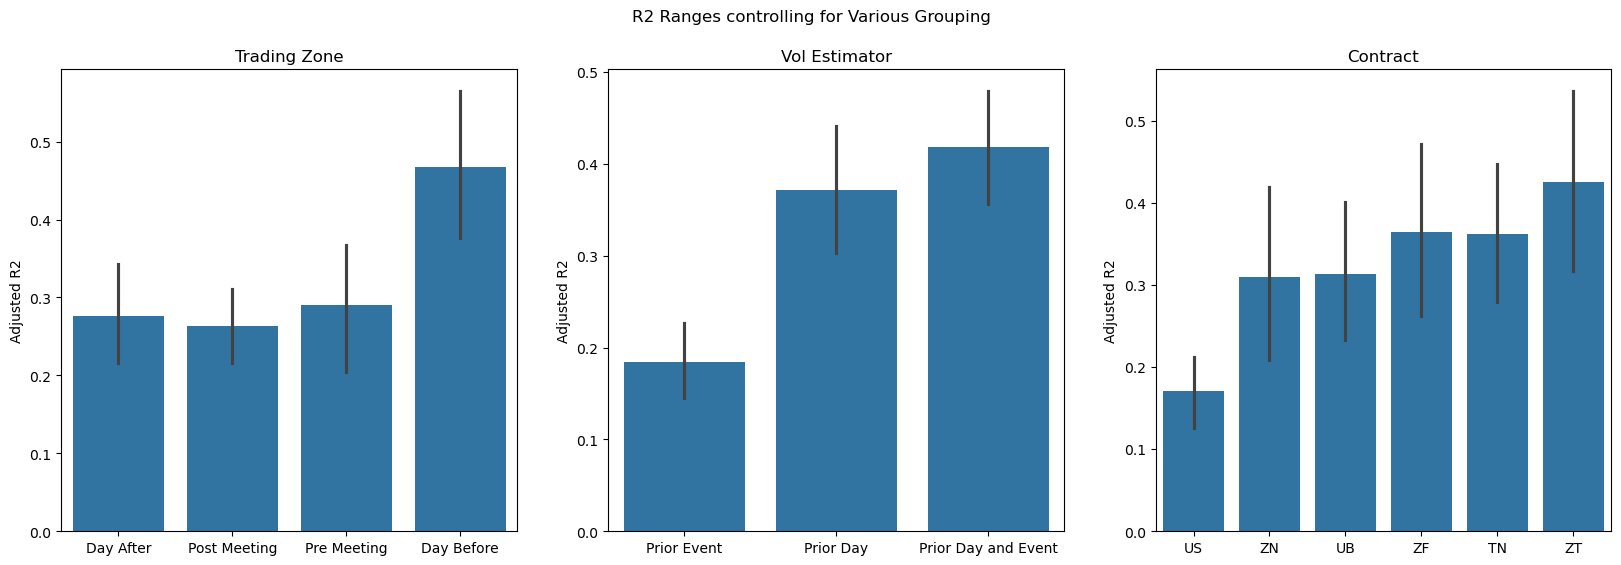

In [20]:
cols      = ["name", "vol_type", "ticker"]
fig, axes = plt.subplots(ncols = len(cols), figsize = (20,6))

for col, ax in zip(cols, axes.flatten()): 

    df_plot = df_r2.replace(replacer)
    
    order = (df_plot
        .groupby(col)["adj_r2"]
        .median()
        .sort_values()
        .index)

    sns.barplot(
        ax    = ax,
        data  = df_plot,
        x     = col,
        y     = "adj_r2",
        order = order)

    ax.set_ylabel("Adjusted R2")
    ax.set_title(replacer[col])
    ax.set_xlabel("")

fig.suptitle("R2 Ranges controlling for Various Grouping")
plt.show()

In [21]:
cols     = ["name", "vol_type", "ticker"]
df_lists = [] 

for col in cols: 

    df_add = (df_params
        [[col, "adj_r2"]]
        .groupby(col)
        .agg("mean")
        .reset_index()
        .rename(columns = {col: "stat"})
        .assign(name = col))
    
    df_lists.append(df_add)

In [22]:
df_avg_r2 = (pd
    .concat(df_lists)
    .replace(replacer)
    .sort_values("adj_r2")
    .rename(columns = {"name": ""}))

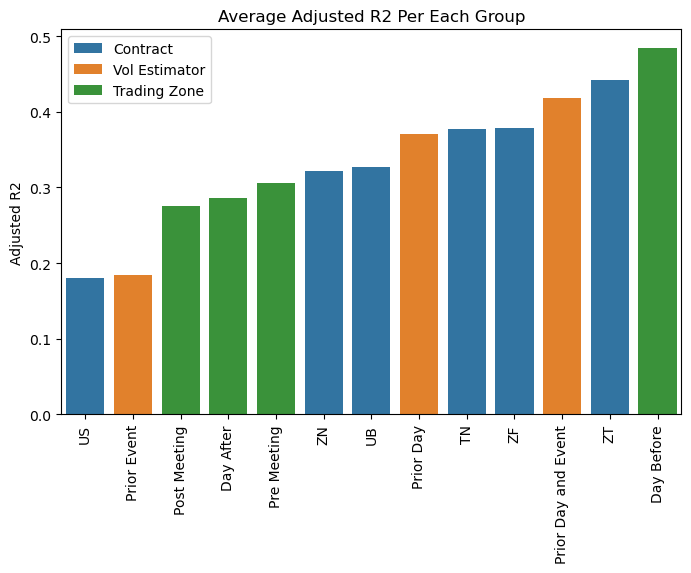

In [23]:
fig, axes = plt.subplots(figsize = (8,5))

sns.barplot(
    data = df_avg_r2,
    x    = "stat",
    y    = "adj_r2",
    hue  = "",
    ax   = axes)

axes.tick_params(axis = "x", rotation = 90)
axes.set_xlabel("")
axes.set_ylabel("Adjusted R2")
axes.set_title("Average Adjusted R2 Per Each Group")
plt.show()

# Generating Tradeable Backtest

Before we apply the signal we need to build a tradeable backtest. The idea is that we need to make vol-normalized returns before we can go about trading them. To do se we have to examine the in-sample and out-of-sample volatility targeted methods. There are two methods for using volatility as an inputted factor into for prediction the first is prior event and prior day, and a third method that combines the two. Prior event was used because these are specific events and we ideally trading a repetable pattern therefore the volatilities should be similar. Prior day uses the prior day since there may be time-varying factors from the prior event that cause the volatility to be different. 

Using the combined volatility method generates an extra ~10% in adjusted $R^2$. Therefore we will used the combined volatility estimator.  

In [24]:
(df_params
    [["name", "adj_r2", "ticker", "zone", "vol_type"]]
    .drop_duplicates()
    .pivot(index = ["ticker", "zone", "name"], columns = "vol_type", values = "adj_r2")
    .reset_index()
    .melt(id_vars = ["ticker", "zone", "name", "combined"])
    .assign(diff = lambda x: x.combined - x.value)
    [["ticker", "zone", "name", "diff"]]
    .groupby(["ticker", "zone", "name"])
    .agg("mean")
    .reset_index()
    .replace(replacer)
    .rename(columns = {"ticker": ""})
    .pivot(index = ["zone", "name"], columns = "", values = "diff"))

,,TN,UB,US,ZF,ZN,ZT
zone,name,,,,,,
After Meeting,Post Meeting,0.116928,0.106051,0.076774,0.133553,0.111314,0.164737
Before Meeting,Pre Meeting,0.179067,0.132044,0.117584,0.187441,0.154532,0.200173
Day After,Day After,0.133963,0.145447,0.075921,0.077897,0.058967,0.147449
Day Before,Day Before,0.192501,0.198433,0.112421,0.183011,0.196134,0.171769


In [25]:
vol_path = os.path.join(data_path, "VolatilityNormalizedReturns")
files    = ["InSample", "OutSample"]
paths    = [os.path.join(vol_path, file + ".parquet") for file in files]

df_normalized = (pd
    .read_parquet(path = paths)
    .loc[lambda x: x.vol_type == "combined"])

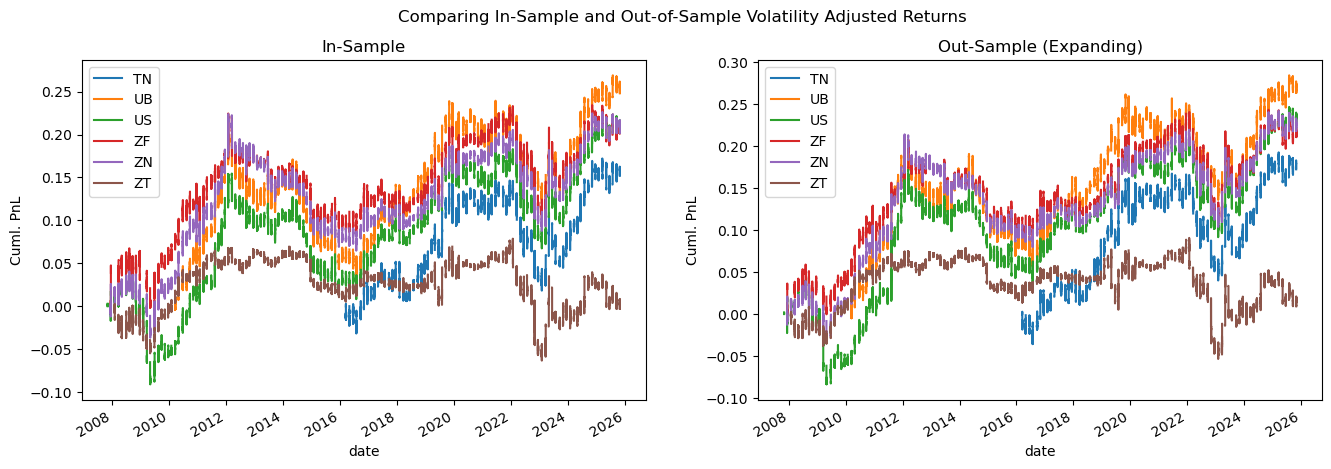

In [26]:
vol_samples = df_normalized.vol_sample.drop_duplicates().sort_values().to_list()

renamer = {
    "is": "In-Sample",
    "os": "Out-Sample (Expanding)"}

fig, axes   = plt.subplots(ncols = len(vol_samples), figsize = (16,5))

for vol_sample, ax in zip(vol_samples, axes.flatten()): 

    (df_normalized
        .loc[lambda x: x.vol_sample == vol_sample]
        .rename(columns = {"ticker": ""})
        .pivot(index = "date", columns = "", values = "vol_rtn")
        .cumsum()
        .plot(
            ax     = ax,
            title  = renamer[vol_sample],
            ylabel = "Cuml. PnL"))

fig.suptitle("Comparing In-Sample and Out-of-Sample Volatility Adjusted Returns")
plt.show()

In [27]:
df_full_corr = (df_normalized
    .pivot(index = ["date", "ticker"], columns = "split", values = "vol_rtn")
    .reset_index()
    .drop(columns = ["date"])
    .groupby("ticker")
    .agg("corr")
    .loc[lambda x: x.oos != 1]
    .reset_index()
    [["ticker", "oos"]]
    .assign(name = "all"))

In [28]:
df_full_corr.head()

split,ticker,oos,name
0,TN,0.989668,all
1,UB,0.994214,all
2,US,0.994628,all
3,ZF,0.986128,all
4,ZN,0.990482,all


In [29]:
df_zone_corr = (df_normalized
    .pivot(index = ["date", "name", "ticker"], columns = "split", values = "vol_rtn")
    .reset_index()
    .drop(columns = ["date"])
    .groupby(["name", "ticker"])
    .agg("corr")
    .reset_index()
    .loc[lambda x: x.oos != 1]
    .drop(columns = ["full", "split"]))

In [30]:
df_zone_corr.head(5)

split,name,ticker,oos
0,day_after,TN,0.995709
2,day_after,UB,0.997423
4,day_after,US,0.995879
6,day_after,ZF,0.985822
8,day_after,ZN,0.988918


The corerlations are measured between the in-sample and out-of-sample volatility estimators which show a strong correlation to each other implying that the volatility estimates are quite strong. 

In [31]:
(pd
    .concat([df_full_corr, df_zone_corr])
    .rename(columns = {"name": ""})
    .replace(replacer)
    .pivot(index = "ticker", columns = "", values = "oos"))

,Day After,Day Before,Post Meeting,Pre Meeting,all
ticker,,,,,
TN,0.995709,0.998379,0.968983,0.988016,0.989668
UB,0.997423,0.998176,0.974119,0.995780,0.994214
US,0.995879,0.998065,0.977246,0.997759,0.994628
ZF,0.985822,0.998364,0.970945,0.992711,0.986128
ZN,0.988918,0.998382,0.980960,0.996704,0.990482
ZT,0.994621,0.999228,0.970982,0.997680,0.989932


# Strategy 1: Historical Event Average

Now that the volatility normalized returns have been created we can begin by generating a signal and backtesting it. The signal we will first start is quite generic it is simply taking the mean of the prior period event. For the out-of-sample piece this is done by taking the expanding average over the period.

In [35]:
signal_generator = SignalGenerator()
signal_name      = "HistoricalEventMean"

vol_types = ["combined"]
schemes   = ["in_sample", "train_test", "out_sample"]

df_signal_rtn = (pd
    .concat([
        signal_generator.apply_signal(
            signal_name = signal_name,
            scheme      = scheme,
            vol_types   = vol_types)
        for scheme in schemes]))

In [42]:
schemes = (df_signal_rtn
    .scheme
    .drop_duplicates()
    .sort_values().to_list())

Now generate the backtest of applying the signal and playback the results, which show that its quite difficult to apply this signal naively

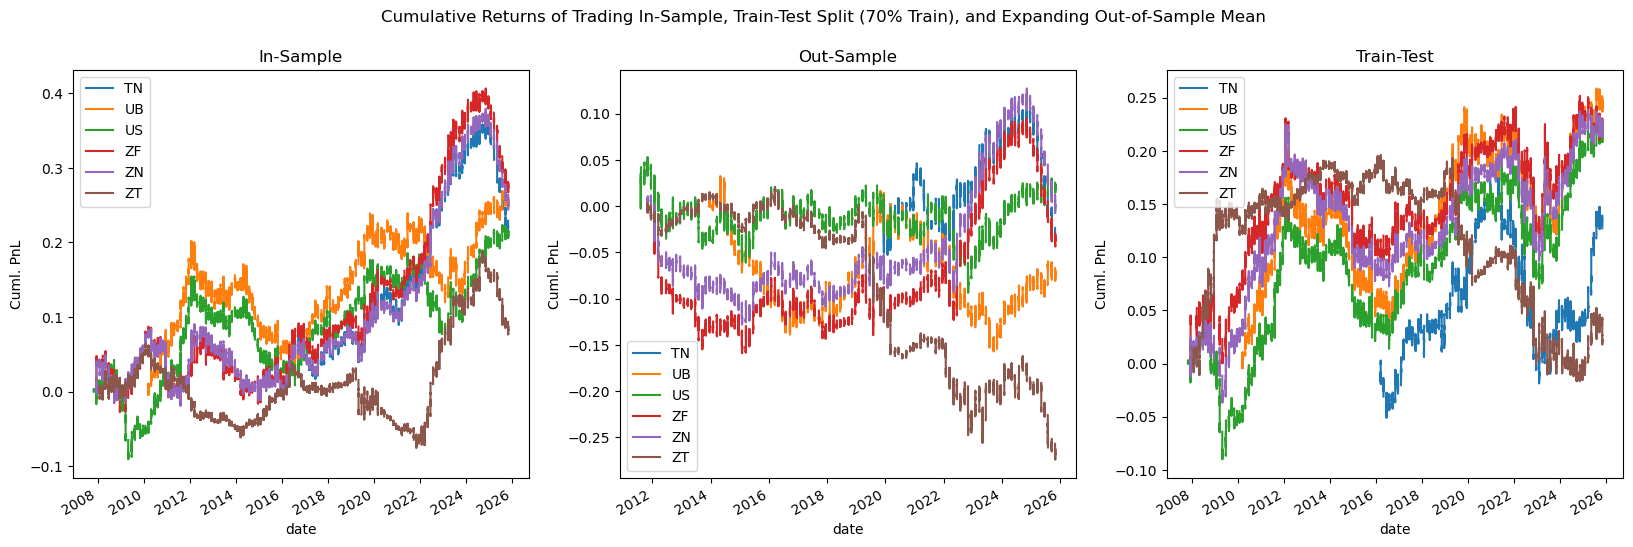

In [70]:
fig, axes = plt.subplots(ncols = len(schemes), figsize = (20,6))

for scheme, ax in zip(schemes, axes.flatten()): 

    (df_signal_rtn
        .loc[lambda x: x.scheme == scheme]
        .rename(columns = {"ticker": ""})
        .pivot(index = "date", columns = "", values = "signal_rtn")
        .cumsum()
        .plot(
            ax     = ax,
            title  = replacer[scheme],
            ylabel = "Cuml. PnL"))

fig.suptitle("Cumulative Returns of Trading In-Sample, Train-Test Split (70% Train), and Expanding Out-of-Sample Mean")
plt.show()

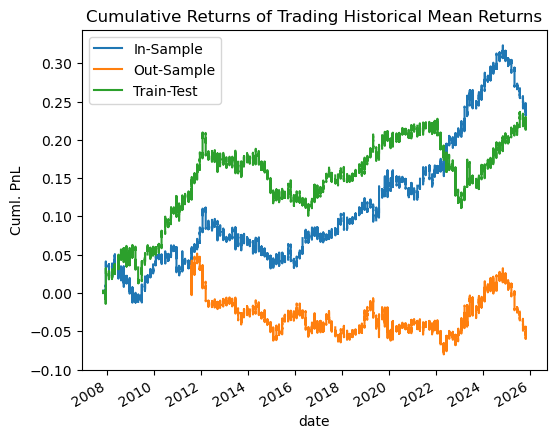

In [71]:
(df_signal_rtn
    [["date", "scheme", "signal_rtn"]]
    .groupby(["date", "scheme"])
    .agg("mean")
    .reset_index()
    .rename(columns = {"scheme": ""})
    .pivot(index = "date", columns = "", values = "signal_rtn")
    .cumsum()
    .rename(columns = replacer)
    .plot(
        ylabel  = "Cuml. PnL",
        title   = "Cumulative Returns of Trading Historical Mean Returns",
        figsize = (6,5)))

plt.show()

In [72]:
(df_signal_rtn)

,meeting_id,ticker,contract,zone,name,date,impute_open,vol_est,vol_type,ann_vol,...,signal,position,signal_rtn,vol_source,model_vol_est,empirical_vol_est,n_obs,train_last_meeting,cutoff_meeting,model_meeting_id
0,90,US,H08,zone1,day_before,2007-10-30 09:30:00,NaN,0.042115,combined,0.831696,...,9.992219e-07,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,90,US,H08,zone1,day_before,2007-10-30 09:31:00,NaN,0.042115,combined,0.831696,...,9.992219e-07,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,90,US,H08,zone1,day_before,2007-10-30 09:32:00,0.000000,0.042115,combined,0.831696,...,9.992219e-07,1.0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,90,US,H08,zone1,day_before,2007-10-30 09:33:00,NaN,0.042115,combined,0.831696,...,9.992219e-07,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,90,US,H08,zone1,day_before,2007-10-30 09:34:00,NaN,0.042115,combined,0.831696,...,9.992219e-07,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
609573,237,ZT,Z25,zone4,day_after,2025-10-30 15:26:00,0.007812,0.003889,combined,0.076805,...,1.375783e-07,1.0,0.001017,model,0.003889,0.004516,142.0,NaN,NaN,236.0
609574,237,ZT,Z25,zone4,day_after,2025-10-30 15:27:00,-0.003906,0.003889,combined,0.076805,...,1.375783e-07,1.0,-0.000509,model,0.003889,0.004516,142.0,NaN,NaN,236.0
609575,237,ZT,Z25,zone4,day_after,2025-10-30 15:28:00,-0.003906,0.003889,combined,0.076805,...,1.375783e-07,1.0,-0.000509,model,0.003889,0.004516,142.0,NaN,NaN,236.0
609576,237,ZT,Z25,zone4,day_after,2025-10-30 15:29:00,0.000000,0.003889,combined,0.076805,...,1.375783e-07,1.0,0.000000,model,0.003889,0.004516,142.0,NaN,NaN,236.0
